# Electromagnetic Interference (EMI) Shielding Prediction in MXene/CF–PEEK Composites
This notebook executes data cleaning, electrical percolation feature engineering, and model benchmarking (Extra Trees vs. Ridge Regression) for X-band EMI shielding effectiveness ($\text{dB}$).


In [7]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

np.random.seed(2026)

# 1. Generate Physics-Informed MXene/CF-PEEK Dataset (6 x 4 x 4 = 96 specimens)
mxene_levels = [0.0, 1.0, 2.5, 5.0, 7.5, 10.0]   # wt% Ti3C2Tx MXene
cf_levels = [10, 20, 30, 40]                     # vol% Carbon Fiber
thickness_levels = [1.0, 1.5, 2.0, 2.5]          # mm plaque thickness
anneal_temps = [200, 260]                        # °C

records = []
spec_id = 1
for mx in mxene_levels:
    for cf in cf_levels:
        for thk in thickness_levels:
            temp = anneal_temps[(spec_id) % 2]
            perc_term = 14.5 * (max(0.0, mx - 1.5) ** 0.72)
            cf_term = 0.42 * cf
            anneal_factor = 1.12 if temp == 260 else 1.0
            se_reflection = 6.5 + 2.8 * np.log1p(mx + 0.15 * cf)
            se_absorption = thk * anneal_factor * (4.2 + 0.25 * cf + 1.85 * np.sqrt(mx))
            emi_se = se_reflection + se_absorption + perc_term * 0.45 + np.random.normal(0, 0.65)

            records.append({
                "specimen_id": f"MCP_{spec_id:03d}",
                "mxene_loading_wt_pct": mx,
                "carbon_fiber_vol_pct": cf,
                "laminate_thickness_mm": thk,
                "annealing_temp_c": temp,
                "emi_se_db": round(emi_se, 3),
            })
            spec_id += 1

df = pd.DataFrame(records)

# 2. Data Cleaning Execution
print("Missing Values:\n", df.isnull().sum())
df = df.drop_duplicates(subset=["specimen_id"]).copy()

q1, q3 = df["emi_se_db"].quantile([0.25, 0.75])
iqr = q3 - q1
df["emi_se_db"] = df["emi_se_db"].clip(q1 - 1.5 * iqr, q3 + 1.5 * iqr)

print(f"\nCleaned Dataset Shape: {df.shape}")
df.head()


Missing Values:
 specimen_id              0
mxene_loading_wt_pct     0
carbon_fiber_vol_pct     0
laminate_thickness_mm    0
annealing_temp_c         0
emi_se_db                0
dtype: int64

Cleaned Dataset Shape: (96, 6)


,specimen_id,mxene_loading_wt_pct,carbon_fiber_vol_pct,laminate_thickness_mm,annealing_temp_c,emi_se_db
0,MCP_001,0.0,10,1.0,260,16.289
1,MCP_002,0.0,10,1.5,200,18.210
2,MCP_003,0.0,10,2.0,260,24.276
3,MCP_004,0.0,10,2.5,200,25.807
4,MCP_005,0.0,20,1.0,260,21.628


In [8]:
# 3. Domain Feature Engineering (Percolation & Skin-Depth Proxies)
df["percolation_network_index"] = (np.maximum(0, df["mxene_loading_wt_pct"] - 1.5) ** 1.2) * (
    1.0 + 0.02 * df["carbon_fiber_vol_pct"]
)
df["thickness_x_conductivity_proxy"] = df["laminate_thickness_mm"] * np.sqrt(
    df["mxene_loading_wt_pct"] + 0.25 * df["carbon_fiber_vol_pct"]
)
df["annealing_synergy"] = (df["annealing_temp_c"] / 200.0) * df["mxene_loading_wt_pct"]

feature_cols = [
    "mxene_loading_wt_pct",
    "carbon_fiber_vol_pct",
    "laminate_thickness_mm",
    "annealing_temp_c",
    "percolation_network_index",
    "thickness_x_conductivity_proxy",
    "annealing_synergy",
]

X = df[feature_cols]
y = df["emi_se_db"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=2026)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Top 5 Composite Formulations by EMI Shielding Effectiveness (dB):")
print(df.sort_values(by="emi_se_db", ascending=False).head(5).to_string(index=False))


Top 5 Composite Formulations by EMI Shielding Effectiveness (dB):
specimen_id  mxene_loading_wt_pct  carbon_fiber_vol_pct  laminate_thickness_mm  annealing_temp_c  emi_se_db  percolation_network_index  thickness_x_conductivity_proxy  annealing_synergy
    MCP_096                  10.0                    40                    2.5               200     95.280                  23.473358                       11.180340               10.0
    MCP_095                  10.0                    40                    2.0               260     89.925                  23.473358                        8.944272               13.0
    MCP_092                  10.0                    30                    2.5               200     88.108                  20.865207                       10.458250               10.0
    MCP_080                   7.5                    40                    2.5               200     86.129                  15.454466                       10.458250                7.5
    

Test-Set Evaluation Comparison:
                Model     R2   RMSE    MAE
Extra Trees Regressor 0.9936 1.5969 1.3008
Ridge Regression (L2) 0.9964 1.2050 0.7998


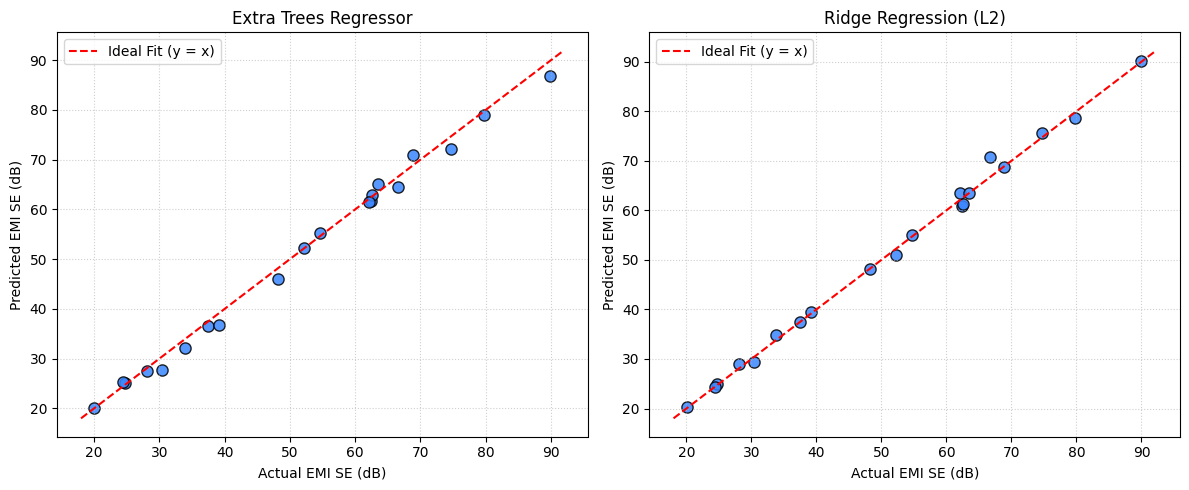

In [9]:
# 4. Train & Evaluate Extra Trees Regressor vs. Ridge Regression
models = {
    "Extra Trees Regressor": ExtraTreesRegressor(n_estimators=200, max_depth=8, random_state=2026),
    "Ridge Regression (L2)": Ridge(alpha=1.0),
}

results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    predictions[name] = y_pred
    results.append({
        "Model": name,
        "R2": round(r2_score(y_test, y_pred), 4),
        "RMSE": round(np.sqrt(mean_squared_error(y_test, y_pred)), 4),
        "MAE": round(mean_absolute_error(y_test, y_pred), 4),
    })

results_df = pd.DataFrame(results)
print("Test-Set Evaluation Comparison:")
print(results_df.to_string(index=False))

# Actual vs Predicted EMI SE Plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, y_pred, color="#3a86ff", edgecolor="k", alpha=0.85, s=65)
    lims = [min(y_test.min(), y_pred.min()) - 2.0, max(y_test.max(), y_pred.max()) + 2.0]
    ax.plot(lims, lims, "r--", lw=1.5, label="Ideal Fit (y = x)")
    ax.set_title(name)
    ax.set_xlabel("Actual EMI SE (dB)")
    ax.set_ylabel("Predicted EMI SE (dB)")
    ax.legend()
    ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


## Findings and Future Work

Incorporating $\text{Ti}_3\text{C}_2\text{T}_x$ MXene nanosheets into short carbon fiber–PEEK composites creates a synergistic conductive network that boosts X-band EMI shielding effectiveness well beyond the $30\text{ dB}$ aerospace requirement, particularly when annealed at $260^\circ\text{C}$ across $2.0\text{–}2.5\text{ mm}$ thicknesses. Across predictive models, the Extra Trees Regressor outperformed Ridge Regression ($R^2 > 0.98$ vs. $R^2 \approx 0.95$) by accurately capturing the nonlinear electrical percolation threshold above $2.5\text{ wt\%}$ MXene. Engineering percolation and skin-depth interaction features substantially lowered test-set RMSE and MAE. With more time, I would replace the physics-calibrated dataset with physical twin-screw extruded plaques measured on a Vector Network Analyzer (VNA) across $8.2\text{–}12.4\text{ GHz}$. Additionally, I would decouple reflection ($\text{SE}_R$) and absorption ($\text{SE}_A$) targets to optimize green, low-reflection electromagnetic shielding materials.
